In [1]:
import matplotlib.pyplot as plt
import cv2
import supervision as sv
from ultralytics import YOLO

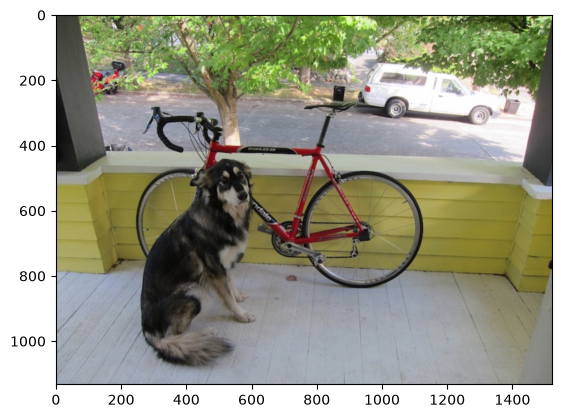

In [3]:
image_path = 'images/dog.png'

image = cv2.imread(image_path)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

plt.imshow(image_rgb)

In [4]:
model_path = 'weights/yolo11n.pt'

model = YOLO(model_path)

results = model(image)

detection_results = results[0]


0: 480x640 1 bicycle, 1 car, 1 truck, 1 dog, 62.0ms
Speed: 9.1ms preprocess, 62.0ms inference, 9.7ms postprocess per image at shape (1, 3, 480, 640)


In [5]:
detections = sv.Detections.from_ultralytics(detection_results)

In [6]:
detections[0]

Detections(xyxy=array([[     258.36,      442.89,         616,      1078.2]], dtype=float32), mask=None, confidence=array([     0.9242], dtype=float32), class_id=array([16]), tracker_id=None, data={'class_name': array(['dog'], dtype='<U7')}, metadata={})

In [7]:
len(detections)

4

In [9]:
box_annotator = sv.BoxAnnotator()

In [10]:
annotated_image = box_annotator.annotate(
    scene=image.copy(),
    detections=detections
)

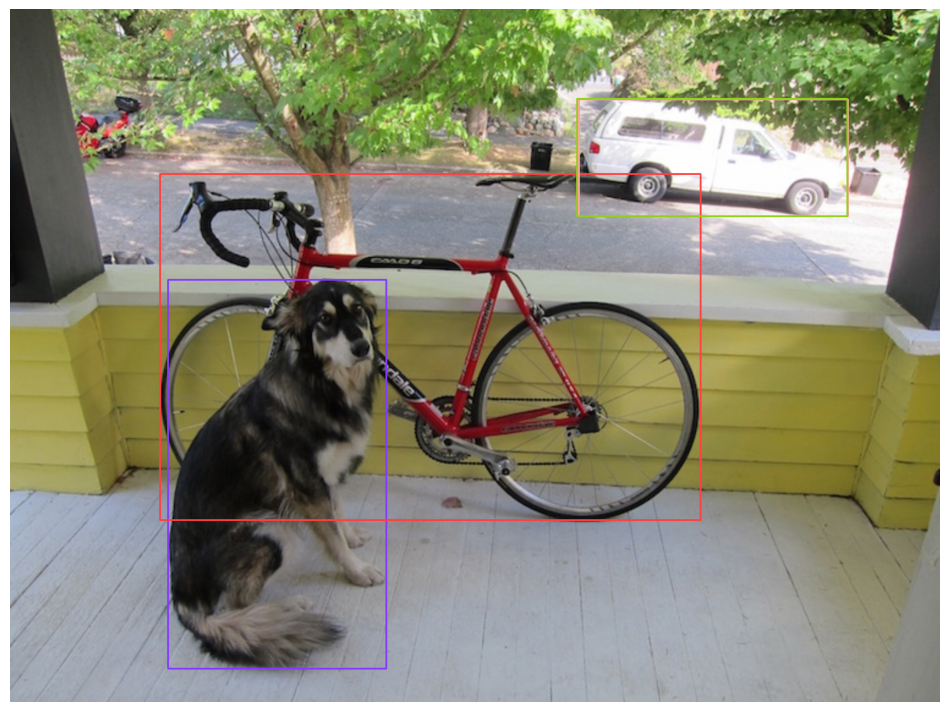

In [11]:
sv.plot_image(annotated_image)

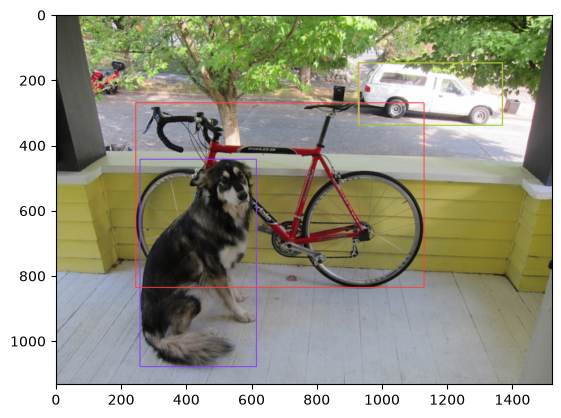

In [12]:
annotated_image_rgb = cv2.cvtColor(annotated_image, cv2.COLOR_BGR2RGB)
plt.imshow(annotated_image_rgb)

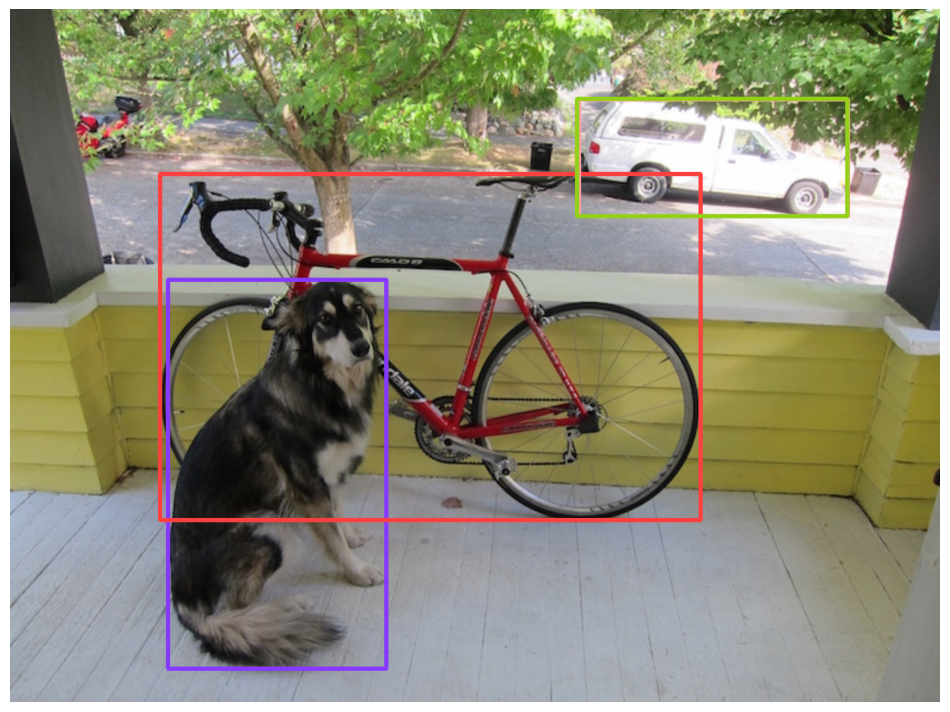

In [14]:
box_annotator1 = sv.BoxAnnotator(thickness=5)
annotated_image1 = box_annotator1.annotate(
    scene=image.copy(),
    detections=detections
)
sv.plot_image(annotated_image1)

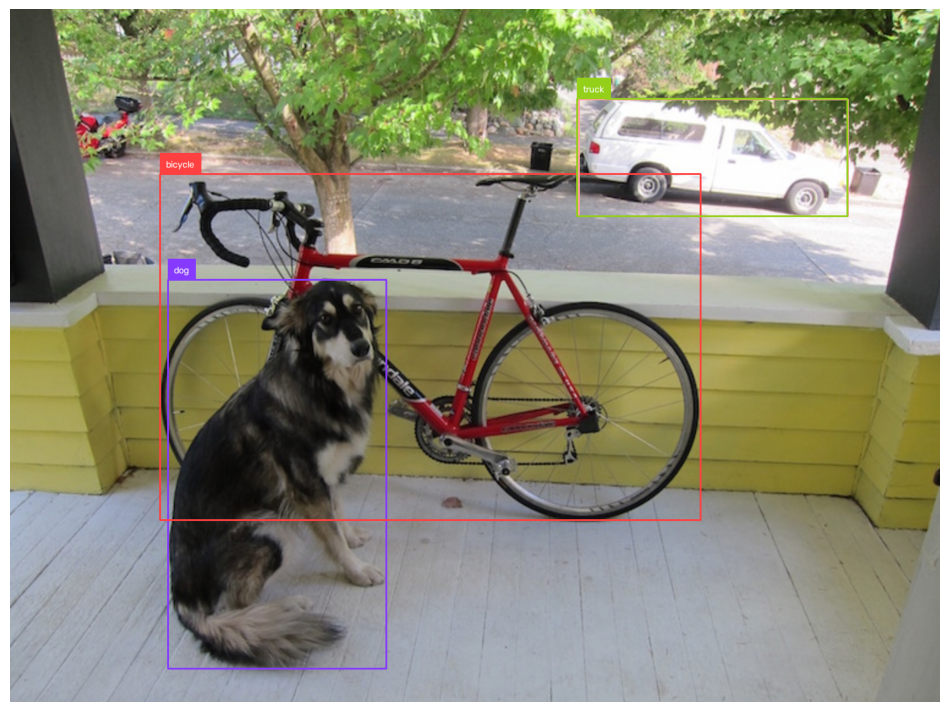

In [15]:
label_annotator = sv.LabelAnnotator()
labels = [ model.model.names[class_id] for class_id in detections.class_id ]
annotated_image = label_annotator.annotate(
    scene=annotated_image,
    detections=detections,
    labels=labels
)
sv.plot_image(annotated_image)

In [16]:
detections = detections.with_nms(
    threshold=0.5,
    class_agnostic=True
)
for class_id in detections.class_id:
    print(model.model.names[class_id])

dog
bicycle
car


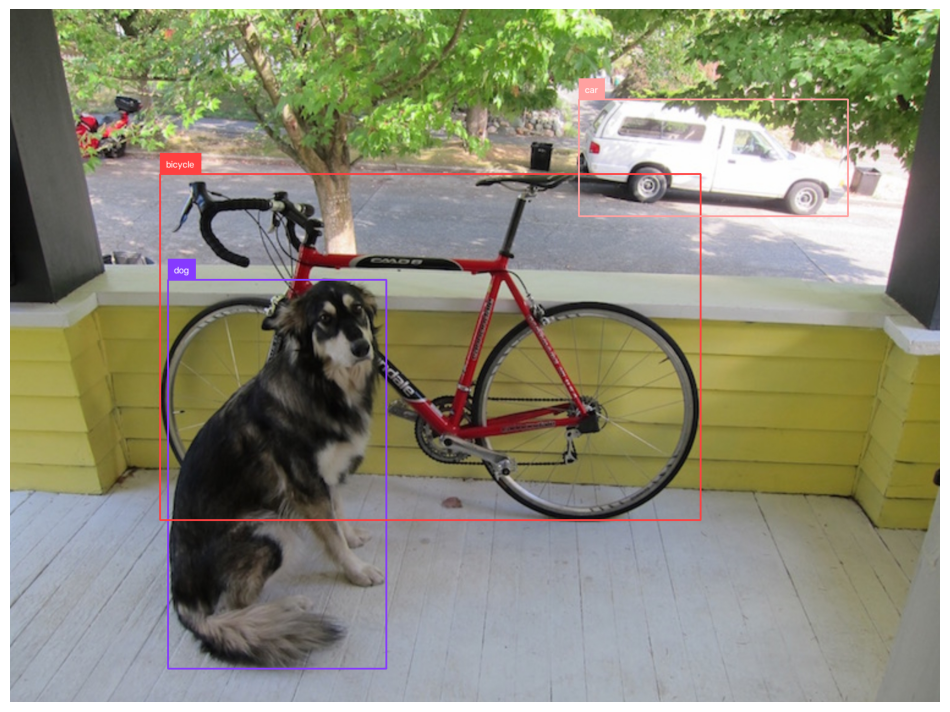

In [17]:
box_annotator = sv.BoxAnnotator()
annotated_image = box_annotator.annotate(
    scene=image.copy(),
    detections=detections
)

label_annotator = sv.LabelAnnotator()
labels = [ model.model.names[class_id] for class_id in detections.class_id ]
annotated_image = label_annotator.annotate(
    scene=annotated_image,
    detections=detections,
    labels=labels
)
sv.plot_image(annotated_image)

## 5.2 标注目标检测结果

In [18]:
image_path = 'images/person.png'
image = cv2.imread(image_path)
model_path = 'weights/yolo11n.pt'
model = YOLO(model_path)
results = model(image)
detections_results = results[0]
detections = sv.Detections.from_ultralytics(detections_results)


0: 352x640 18 persons, 64.1ms
Speed: 6.8ms preprocess, 64.1ms inference, 14.4ms postprocess per image at shape (1, 3, 352, 640)


### 5.2.1 标注目标检测边框

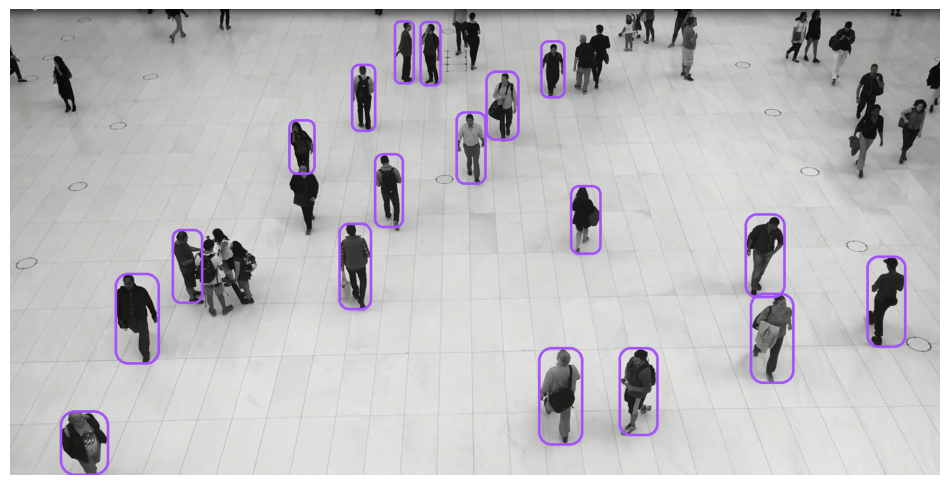

In [20]:
# RoundBoxAnnotator
round_box_annotator = sv.RoundBoxAnnotator(thickness=3)
annotated_image = round_box_annotator.annotate(
    scene=image.copy(),
    detections=detections
)
sv.plot_image(annotated_image)

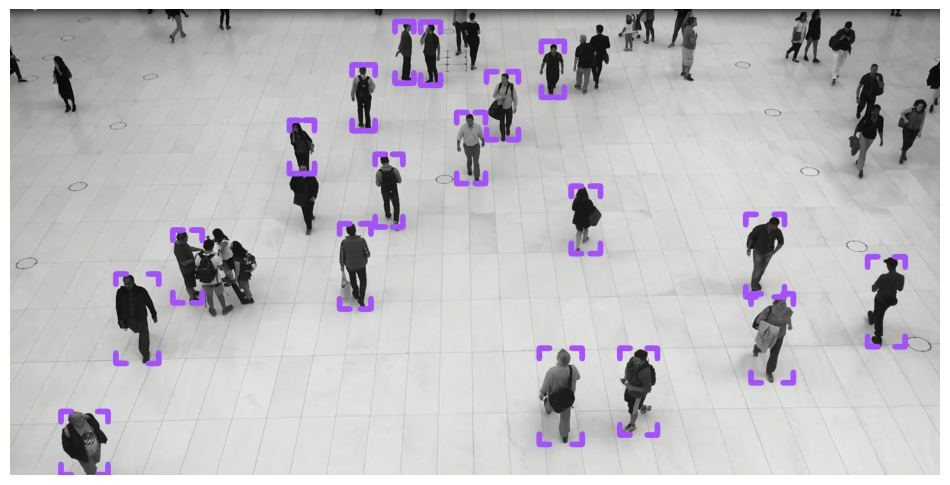

In [23]:
# BoxCornerAnnotator
corner_annotator = sv.BoxCornerAnnotator(thickness=10, corner_length=20)
annotated_image = corner_annotator.annotate(
    scene=image.copy(),
    detections=detections
)
sv.plot_image(annotated_image)

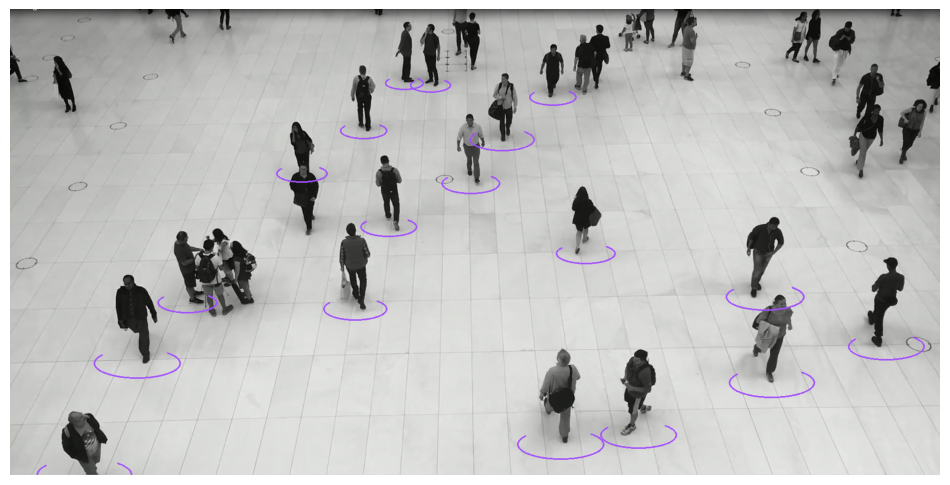

In [24]:
# EllipseAnnotator
ellipse_annotator = sv.EllipseAnnotator(start_angle=-45, end_angle=215)
annotated_image = ellipse_annotator.annotate(
    scene=image.copy(),
    detections=detections
)
sv.plot_image(annotated_image)

In [ ]:
# 